In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/23/2022
# version ='1.0'

# Demo: Further Experiments on Feasibility Detection Using Infeasible Start Newton Method

In book-convex-2004, the infeasible start Newton was applied to the following set of problem to detect the feasibility of $Ax<b+\gamma \Delta b$:

\begin{equation}
\label{eq:NL46-1}
\begin{array}{rl}
\text{minimize} & -\displaystyle{\sum_{i=1}^{m}}\log s_i \\
\text{subject to} & Ax+s = b_0+\gamma \Delta b \\
\end{array}
\end{equation}
where $A\in \mathbf{R}^{m\times n}$. The problem parameters, $A, b_0, \Delta b$ are selected in a way that, when $\gamma > 0$, $Ax<b_0+\gamma \Delta b$ is feasible; when $\gamma < 0$, $Ax<b_0+\gamma \Delta b$ is infeasible. 

Refer to prior demo on the method to construct $A, b_0, \Delta b$.

Let $\hat{A}=[A, I_m]$, $\hat{x}=\left[x; s\right]$ and let $b=b_0+\gamma\Delta b$, then the problem can be rewritten in the standard form as,

\begin{equation}
\label{eq:NL46-2}
\begin{array}{rl}
\text{minimize} & -\displaystyle{\sum_{i=1}^{m}}\log s_i \\
\text{subject to} & \hat{A}\hat{x} = b \\
\end{array}
\end{equation}

In this demo, further experiments are simulated to visualize the behaviour of the infeasible start method for different size of the problem dimensions, i.e. $m$ and $n$.

In the experiment, $$\alpha=0.01, \beta=0.9, x^{(0)}=0, s^{(0)}=\mathbf{1}, \nu^{(0)}$$

In completion of the backtracking line search in the infeasible start Newton method, once $t$ is equal to 1, the Newton iteration will stop as the primal residual is zero, i.e. the feasibility is detected.

In [2]:
import pickle
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import null_space
from scipy.special import exp10

$f([x; s])=-\sum\log s_i$

$\nabla f([x;s])=[0; -1/s]$

$\nabla^2 f([x;s])=[0, 0; 0, 1/(s^2)]$

In [3]:
def my_f(xs, m):
    """
    $f([x; s])=-\sum\log s_i$
    :param xs:
    :param m:
    :return:
    """
    n_hat = len(xs)
    n = n_hat - m
    s = xs[n:]
    return -np.sum(np.log(s))


def my_gradient_f(xs, m):
    """
    $\nabla f([x;s])=[0; -1/s]$
    :param xs:
    :param m:
    :return:
    """
    n_hat = len(xs)
    n = n_hat - m
    s = xs[n:]
    g = np.block([[np.zeros((n, 1))], [-1 / s]])
    return g


def my_hessian_f(xs, m):
    """
    $\nabla^2 f([x;s])=[0, 0; 0, 1/(s^2)]$
    :param xs:
    :param m:
    :return:
    """
    n_hat = len(xs)
    n = n_hat - m
    s = xs[n:]
    H = np.block([[np.zeros((n, n)), np.zeros((n, m))], [np.zeros((m, n)), np.diag(np.squeeze(1 / (s ** 2)))]])
    return H


def my_f_feasible(xs, m):
    """
    It requires s_i > 0 for all i
    :param xs:
    :param m:
    :return:
    """
    n_hat = len(xs)
    n = n_hat - m
    s = xs[n:]
    return np.all(s > 0)

solve the primal-dual Newton step (in the infeasible start Newton method)

In [4]:
def primal_dual_newton_step_f(xs, nu, A_hat, b_hat):
    """
    solve the primal-dual Newton step (in the infeasible start Newton method)
    :param xs:
    :param nu:
    :param A_hat:
    :param b_hat:
    :return:
    """
    m, n_hat = A_hat.shape
    KKT_matrix = np.block([[my_hessian_f(xs, m), A_hat.T], [A_hat, np.zeros((m, m))]])
    minus_residual_dual_primal = -1 * np.block([[my_gradient_f(xs, m) + (A_hat.T @ nu)], [A_hat @ xs - b_hat]])
    if np.linalg.cond(KKT_matrix) < 1 / sys.float_info.epsilon:
        newton_step = np.linalg.inv(KKT_matrix) @ minus_residual_dual_primal
        primal_step = newton_step[0: len(xs)]
        dual_step = newton_step[len(xs):]
        return primal_step, dual_step
    else:
        raise RuntimeError("KKT matrix is not invertible.")

calculate the $r_{dual}(x,\nu)=\nabla f(x)+A^T\nu$, $r_{pri}(x, \nu)=Ax-b$

In [5]:
def residual_f(xs, nu, A_hat, b_hat):
    """
    calculate the $r_{dual}(x,\nu)=\nabla f(x)+A^T\nu$, $r_{pri}(x, \nu)=Ax-b$
    :param xs:
    :param nu:
    :param A_hat:
    :param b_hat:
    :return:
    """
    m, n_hat = A_hat.shape
    r_dual = my_gradient_f(xs, m) + A_hat.T @ nu
    r_pri = A_hat @ xs - b_hat
    return np.block([[r_dual], [r_pri]])

get the norm of residual, $|r_{dual}|$, and $|r_{pri}|$

In [6]:
def residual_dual_primal_norm_f(xs, nu, A_hat, b_hat):
    """
    get the norm of residual, $|r_{dual}|$, and $|r_{pri}|$
    :param xs:
    :param nu:
    :param A_hat:
    :param b_hat:
    :return:
    """
    residual = residual_f(xs, nu, A_hat, b_hat)
    return np.linalg.norm(residual[0: len(xs)]), np.linalg.norm(residual[len(xs):])

get the norm of the residual, $|r|=|[r_{dual}, r_{pri}]|$

In [7]:
def residual_norm_f(xs, nu, A_hat, b_hat):
    """
    get the norm of the residual, $|r|=|[r_{dual}, r_{pri}]|$
    :param xs:
    :param nu:
    :param A_hat:
    :param b_hat:
    :return:
    """
    residual = residual_f(xs, nu, A_hat, b_hat)
    return np.linalg.norm(residual)

backtracking line search method in the infeasible start Newton method

refer to Algorithm 10.2 in the textbook

In [8]:
def backtracking_line_search(xs, nu, d_xs, d_nu, alpha, beta, args):
    """
    backtracking line search method in the infeasible start Newton method
    refer to Algorithm 10.2 in the textbook
    :param xs:
    :param nu:
    :param d_xs:
    :param d_nu:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    m = len(nu)
    t = 1
    r = residual_norm_f
    while (not my_f_feasible(xs + d_xs * t, m)) \
            or r(xs + t * d_xs, nu + t * d_nu, *args) > (1 - alpha * t) * r(xs, nu, *args):
        t = beta * t
    return t

Refer to prior demo on the method to construct $A, b_0, \Delta b$.

In [9]:
def get_A_b0_delta_b(m, n):
    """
    Refer to prior demo on the method to construct $A, b_0, \Delta b$.
    :param m:
    :param n:
    :return:
    """
    if m <= n:
        raise RuntimeError('only supporting m > n scenario.')
    lambda_ = np.random.uniform(low=0, high=1, size=(m, 1))
    ns = null_space(lambda_.T)
    A = ns[:, 0:n]
    y = np.random.normal(loc=0, scale=1.0, size=(n, 1))
    b0 = A @ y
    if not np.allclose(b0.T @ lambda_, 0):
        raise RuntimeError(r'it should guarantee that $b^T \lambda$ = 0')

    z = np.random.normal(loc=0, scale=1.0, size=(n, 1))
    delta_b = A @ z + np.ones((m, 1))

    return A, b0, delta_b, lambda_

get the model parameter according to Equ. 2 in the FlexibleLecture Note.

In [10]:
def get_A_hat_b_xs0_nu(A, b_0, gamma, delta_b):
    """
    get the model parameter according to Equ. 2 in the FlexibleLecture Note.
    :param A:
    :param b_0:
    :param gamma:
    :param delta_b:
    :return:
    """
    (m, n) = A.shape
    A_hat = np.block([[A, np.eye(m)]])
    b = b_0 + gamma * delta_b
    x0 = np.zeros((n, 1))
    s0 = np.ones((m, 1))
    xs0 = np.block([[x0], [s0]])
    nu0 = np.zeros((m, 1))
    return A_hat, b, xs0, nu0

plot the figure in number of iterations required to find a feasible point for a set
of linear inequalities $Ax\preceq b_0+\gamma\Delta b$ versus $\gamma$

In [11]:
def plot_figure_accumulate_newton_iteration_versus_gamma(ms, ns, gammas, n_dial=3):
    """
    plot the figure in number of iterations required to find a feasible point for a set
    of linear inequalities $Ax\preceq b_0+\gamma\Delta b$ versus $\gamma$
    :param ms:
    :param ns:
    :param gammas:
    :param n_dial:
    :return:
    """
    if len(ms) != len(ns):
        raise RuntimeError("It requires the size of the list of m and the list of n be the same.")

    n_m = len(ms)
    n_seed = n_dial
    n_gamma = len(gammas)
    n_iterations = np.zeros((n_m, n_gamma, n_seed))
    for mi in range(n_m):
        m = ms[mi]
        n = ns[mi]

        for gamma_index, gamma in enumerate(gammas):
            for seed in range(n_seed):

                np.random.seed(seed)
                A, b0, delta_b, lambda_ = get_A_b0_delta_b(m, n)
                A_hat, b, xs0, nu0 = get_A_hat_b_xs0_nu(A, b0, gamma, delta_b)

                alpha = 0.01
                beta = 0.9
                epsilon = 1e-10
                zeta = 1e-10  # quantization error checking A_hat [x;s] = b_hat

                xs = xs0.copy()
                nu = nu0.copy()
                args = (A_hat, b)
                MAX_ITERATION = 1000
                iteration = 0
                feasible = False
                while True:
                    d_xs, d_nu = primal_dual_newton_step_f(xs, nu, A_hat, b)
                    step_t = backtracking_line_search(xs, nu, d_xs, d_nu, alpha, beta, args)

                    # r_dual_norm, r_prim_norm = residual_dual_primal_norm_f(x, nu, A_hat, b_hat)
                    # print('Info: [{}]: |r_prim|={},|r_dual|={},t={}'.format(iteration, r_prim_norm, r_dual_norm,
                    # step_t))

                    xs = xs + step_t * d_xs
                    nu = nu + step_t * d_nu

                    iteration += 1

                    if step_t == 1:
                        # print('Info: feasibility detected at iteration={}, because found A_hat @ [x;s] = b_hat'.format(iteration))
                        feasible = True
                        break

                    if np.linalg.norm(A_hat @ xs - b) < zeta and residual_norm_f(xs, nu, A_hat, b) <= epsilon:
                        # print(
                        #     'Info: feasibility detected at iteration={}, when the infeasible start Newton method '
                        #     'converged'.format(iteration))
                        break

                    if iteration >= MAX_ITERATION:
                        print('Error: fail to converge in the infeasible start Newton method.')
                        break

                n_iterations[mi][gamma_index][seed] = iteration
                if feasible:
                    #print('Info: [m={}, n={}, gamma={:0.6f}, seed={} Feasibility detected at iteration = {}'.format(m, n, gamma, seed, iteration))
                    x = xs[0:n]
                    if not np.all(b - (A @ x) > 0):
                        raise RuntimeError('It should be feasible.')
                else:
                    print('Feasibility undetected')

    #fid = open('n_iteration_{}.pickle'.format(np.random.sample()), 'wb')
    #pickle.dump(n_iterations, fid)
    #fid.close()

    avg_num_iter = np.average(n_iterations, axis=2)
    std_num_iter = np.std(n_iterations, axis=2)

    for mi in range(n_m):
        plt.errorbar(gammas, avg_num_iter[mi], yerr=std_num_iter[mi], label=r'm={},n={}'.format(ms[mi], ns[mi]))

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel(r'$\gamma$')
    plt.ylabel(r'total iterations')
    plt.legend()
    plt.grid()
    plt.show()

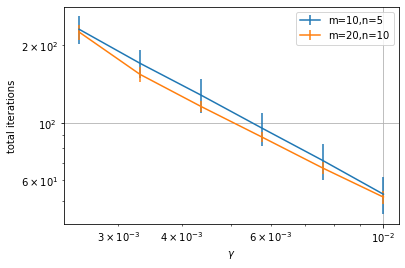

In [12]:
if __name__ == "__main__":
    ms = [10, 20]
    ns = [5, 10]
    gammas = exp10(np.linspace(start=-2.6, stop=-2, num=6, endpoint=True))
    plot_figure_accumulate_newton_iteration_versus_gamma(ms=ms, ns=ns, gammas=gammas)
